In [16]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/23/2022
# version ='1.0'

# Demo: Further Experiments on Solving A Family of Linear Feasibility Problem by Basic Phase I Method

In book-convex-2004, the basic phase I method was applied to a family of linear feasibility problems to evaluate the number of Newton steps to detect feasibility, or prove infeasibility for problems very near the boundary between feasible and infeasible.
\begin{equation}
\begin{array}{rcl}
Ax & \preceq & b+\gamma \Delta b \\
\end{array}
\end{equation}


where $A\in \mathbf{R}^{m\times n}$, and $m>n$. According to the theorems of alternatives, the strong alternative is
\begin{equation}
\begin{array}{rcl}
\lambda \succeq 0, & A^T\lambda = 0, & (b+\gamma\Delta b)^T\lambda < 0 \\
\end{array}
\end{equation}

The problem parameters $A, b, \Delta b$ are constructed in the following algorithm such that: 
\begin{itemize}
\item If $\gamma>0$, then Equ.2 is infeasible, thus Equ. 1 is feasible.
\item If $\gamma<0$, then Equ.2 is feasible, thus Equ. 1 is infeasible.
\end{itemize}


### Procedure to generate parameters $(A, b, \Delta b)$

1. Let $\lambda\in \mathbf{U}(0,1)^m$

1. In the null space of $\lambda$, i.e. $\mathcal{N}(\lambda)$, which is of $m-1$ dimensions, select $n$ basis as the column vectors of $A$, so that $A\in\mathbf{R}^{m\times n}$ and $A^T\lambda=0$

1. Randomly select $b\in \mathcal{R}(A)$, i.e. $b=Ay$ for any one of $y\in \mathbf{R}^n$. In this way, $b\in \mathcal{R}(A)\bot \mathcal{N}(A^T)\ni \lambda$, so, $b\bot \lambda$, $b^T\lambda=0$

1. Select $\Delta$ $b=Az+\mathbf{1}$ for any one of $z\in \mathbf{R}^n$. In this way, $\gamma\Delta b^T\lambda  = \gamma \mathbf{1}^T\lambda$. When $\gamma>0$, Equ. 2 is always infeasible; when $\gamma<0$, Equ. 1 is always feasible.


For each $\gamma$, the basic phase I method is to solve the following LP:

\begin{equation}
\begin{array}{rl}
minimize & s  \\
subject to & Ax \preceq \hat{b} + s\mathbf{1}  \\
\end{array}
\end{equation}

where, $\hat{b}=b+\gamma \Delta b$.


Its dual problem is 

\begin{equation}
\begin{array}{rl}
maximize & -\hat{b}^T\lambda \\
subject to & A^T\lambda = 0 \\
& \mathbf{1}^T\lambda = 1 \\
& \lambda \succeq 0 \\
\end{array}
\end{equation}

When using the barrier method to solve Equ. 3 for any $t$, it is to solve the following convex optimization problem by Newton method,
\begin{equation}
\label{eq:NL45-5}
\begin{array}{rl}
\text{minimize} & ts -\displaystyle{\sum_i}\log(s+\hat{b}_i-a_i^Tx) \\
\end{array}
\end{equation}

It can be proved that, if $(x^*(t), s^*(t))$ is the optimal solution in Equ. 5, then 
$$
\lambda^*(t)=\dfrac{1}{t(s+\hat{b}_i-a_i^Tx)}
$$
is dual feasible in Equ. 4,  thus, $-\hat{b}^T\lambda^*(t)$ is a lower bound of $s$ and can be used for infeasibility detection.

The algorithm of detecting the feasibility or infeasibility of Equ. 1 is summarized in the Algorith in the following:



### Algorithm to detect feasibility or infeasibility of Equ. 1]


For t=$t_0\beta^K$, $K=0,1,...,N-1$

1. Solve the convex problem in Equ. 5 by Newton method, to get the optimal solution $(x^*(t), s^*(t))$

1. Let $\lambda^*(t)=\dfrac{1}{t(s^*(t)+\hat{b}_i-a_i^Tx^*(t))}$

1. If $s^*(t)<-\zeta$, then Equ. 1 is feasible; break

1. Else if $-\hat{b}^T\lambda^*(t)>\zeta$, then Equ. 1 is infeasible; break 

EndFor


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredText
from scipy.linalg import null_space
from scipy.special import exp10

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [18]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    Refer to FlexibleLecture note
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-1\sum(\log(b-Ax)$

$\nabla \phi(x)=A^T \dfrac{1}{b-Ax}$

$\nabla^2 \phi(x)=A^T \left[diag(\dfrac{1}{(b-Ax)^2})\right] A$

In [19]:
def my_phi(x, t, A, b, c):
    """
    $\phi(x)=-1\sum(\log(b-Ax)$
    Refer to FlexibleLecture note
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 * np.sum(np.log(b - A @ x))


def my_phi_feasible(x, t, A, b, c):
    return np.all(b - A @ x > 0)


def my_gradient_phi(x, t, A, b, c):
    """
    $\nabla \phi(x)=A^T \dfrac{1}{b-Ax}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    g = A.T @ (1 / (b - A @ x))
    return g


def my_hessian_phi(x, t, A, b, c):
    """
    $\nabla^2 \phi(x)=A^T \left[diag(\dfrac{1}{(b-Ax)^2})\right] A$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    diag = np.diag(np.squeeze((1/(b - A @ x) ** 2)))
    hessian = A.T @ diag @ A
    return hessian

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [20]:
def my_f(x, t, A, b, c):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_f_0(x, t, A, b, c) + my_phi(x, t, A, b, c)


def my_f_feasible(x, t, A, b, c):
    return my_f_0_feasible(x, t, A, b, c) and my_phi_feasible(x, t, A, b, c)


def my_gradient_f(x, t, A, b, c):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_gradient_f_0(x, t, A, b, c) + my_gradient_phi(x, t, A, b, c)


def my_hessian_f(x, t, A, b, c):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_hessian_f_0(x, t, A, b, c) + my_hessian_phi(x, t, A, b, c)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [21]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    (t, A, b, c) = args
    (m, n) = A.shape
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt_w = np.linalg.inv(KKT) @ (-1 * residual)
        x_nt = x_nt_w[0: n]
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invisible')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [22]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [23]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, A, b, c, max_newton_iteration=100):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    x = x0
    args = (barrier_t, A, b, c)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_searching_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]

    iteration = 1
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        #print(r'iteration={}, decrement={}, t={}'.format(iteration, decrement, t))

        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        line_searching_steps.append(t)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

        if iteration > max_newton_iteration:
            print('Error: Newton method not converged!')
            break

    #print(r'iteration={}, decrement={}'.format(iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_searching_steps

Procedure to generate parameters $(A, b, \Delta b)$

Refer to the FlexibleLecture Note

In [24]:
def get_A_b0_delta_b(m, n):
    """
    Procedure to generate parameters $(A, b, \Delta b)$
    Refer to the FlexibleLecture Note
    :param m:
    :param n:
    :return:
    """
    if m <= n:
        raise RuntimeError('only supporting m > n scenario.')
    lambda_ = np.random.uniform(low=0, high=1, size=(m, 1))
    ns = null_space(lambda_.T)
    A = ns[:, 0:n]
    y = np.random.normal(loc=0, scale=1.0, size=(n, 1))
    b0 = A @ y
    if not np.allclose(b0.T @ lambda_, 0):
        raise RuntimeError(r'it should guarantee that $b^T \lambda$ = 0')

    z = np.random.normal(loc=0, scale=1.0, size=(n, 1))
    delta_b = A @ z + np.ones((m, 1))

    return A, b0, delta_b, lambda_

 Get the parameters of the LP, which is extended from the basic phase I method
 
 Refer to the FlexibleLecture Note

In [25]:
def get_A_b_c_xs0(A, b):
    """
    Get the parameters of the LP, which is extended from the basic phase I method
    Refer to the FlexibleLecture Note
    :param A:
    :param b:
    :return:
    """
    (m, n) = A.shape
    n_hat = n + 1  # an additional variable s
    c_hat = np.zeros((n_hat, 1))
    c_hat[-1] = 1
    A_hat = np.block([[A, -np.ones((m, 1))]])
    b_hat = b
    x0 = np.zeros((n, 1))
    s0 = np.max(-b_hat) + 1  # plus 1 as the margin so that Ax <= d + s is feasible at x0, s0
    xs0 = np.block([[x0], [s0]])
    if not np.all(A_hat @ xs0 < b_hat):
        raise RuntimeError('it is requiring the start point is strictly feasible!')
    return A_hat, b_hat, c_hat, xs0

Run the algorithm to detect feasibility or infeasibility for the LP problem and plot the figure

In [26]:
def plot_linear_feasible_LP_figure(m, n, mu, gammas, seed):
    """
    Run the algorithm to detect feasibility or infeasibility for the LP problem and plot the figure
    :param gammas:
    :param m:
    :param n:
    :param mu:
    :return:
    """
    np.random.seed(seed)
    plt.figure(figsize=(12, 6))
    ax = plt.subplot(1, 1, 1)
    A, b0, delta_b, lambda_ = get_A_b0_delta_b(m, n)
    num_iteration = np.zeros((len(gammas), 1))

    for gamma_index, gamma in enumerate(gammas):
        #print('Info: running experiment for gamma ={}'.format(gamma))
        b = b0 + gamma * delta_b

        A_hat, b_hat, c_hat, xs0 = get_A_b_c_xs0(A, b)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-8
        zeta = 1e-8
        duality_gap_epsilon = n * 1e-6

        t0 = 1
        t = t0
        xs_0 = xs0
        accumulate_iteration = 0

        while True:
            args = (t, A_hat, b_hat, c_hat)
            xs_t, n_iter, f_xs, decrement, step_xs = centering_step(xs_0, epsilon, alpha, beta, *args)
            xs_0 = xs_t
            accumulate_iteration = accumulate_iteration + n_iter

            # to check if it is already feasible or infeasible
            s_p = my_f_0(xs_0, *args)
            if s_p < -zeta:
                #print('Info: It is feasible at iteration = {}, s_p={}'.format(accumulate_iteration, s_p))
                num_iteration[gamma_index] = accumulate_iteration
                # d = b_x - A_x @ (xs_0[0: n_x])
                # print('Info: min diff = {}'.format(np.min(d)))
                # lambda_t = 1 / t * (1 / (s_p + b_x - A_x @ (xs_0[0: n_x])))
                # print('Info: -b_x^T lambda={}'.format(-b_x.T @ lambda_t))
                break
            else:
                lambda_t = 1 / t * (1 / (s_p + b - A @ (xs_0[0: n])))
                if not np.allclose(np.sum(lambda_t), 1, atol=1e-3):
                    raise RuntimeError(r'It is expecting that $1^T \lambda = 1$')
                if not np.all(lambda_t > 0):
                    raise RuntimeError(r'It is expecting that all $\lambda \geq $  0')
                if not np.allclose(A.T @ lambda_t, 0, atol=1e-3):
                    raise RuntimeError(r'It is expecting that $A^T\lambda=0$')
                if -b.T @ lambda_t > zeta:
                    print('Info: It is infeasible at iteration = {}'.format(accumulate_iteration))
                    # print('Info: -b_x^T lambda={}'.format(-b_x.T @ lambda_t))
                    num_iteration[gamma_index] = accumulate_iteration
                    break

            if m / t < duality_gap_epsilon:  # stop when reaching below the duality gap, no decision for feasibility.
                num_iteration[gamma_index] = accumulate_iteration
                break
            else:
                t = mu * t

    ax.plot(gammas, num_iteration, marker='o', fillstyle='none',
            label=r'#Newton steps for $Ax\preceq b(\gamma),m={},n={}$'.format(m, n))
    ax.plot([0, 0], [0, 100], linestyle='dotted')
    ax.set_ylim([0, 100])
    ax.set_xlabel(r'$\gamma$')
    ax.set_ylabel('Newton iteration')
    ax.legend()
    ax.grid()
    # at = AnchoredText(
    #     "Infeasible", prop=dict(size=15), frameon=True, loc='lower left')
    # at.patch.set_boxstyle("round,pad=0.,rounding_size=0.2")
    # ax.add_artist(at)
    # at = AnchoredText(
    #     "Feasible", prop=dict(size=15), frameon=True, loc='lower right')
    # at.patch.set_boxstyle("round,pad=0.,rounding_size=0.2")
    # ax.add_artist(at)
    plt.show()

In [27]:
def plot_pos_neg_gamma():
    gamma_pos = [1 / (2 ** k) for k in range(0, 30)]
    gamma_neg = [-x for x in gamma_pos]
    gammas = np.sort(np.array(gamma_pos + gamma_neg))
    plot_linear_feasible_LP_figure(m=200, n=100, mu=10, gammas=gammas, seed=1)


def plot_pos_gamma():
    gammas = exp10([x for x in np.linspace(start=-6, stop=0, num=13)])
    plot_linear_feasible_LP_figure(m=200, n=100, mu=10, gammas=gammas, seed=1)


def plot_neg_gamma():
    gammas = -1 * exp10([x for x in np.linspace(start=-6, stop=0, num=13)])
    plot_linear_feasible_LP_figure(m=200, n=100, mu=10, gammas=gammas, seed=1)

Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infe

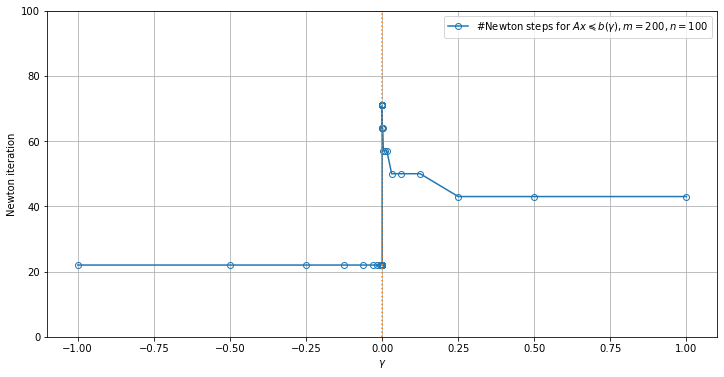

In [28]:
if __name__ == "__main__":
    plot_pos_neg_gamma()

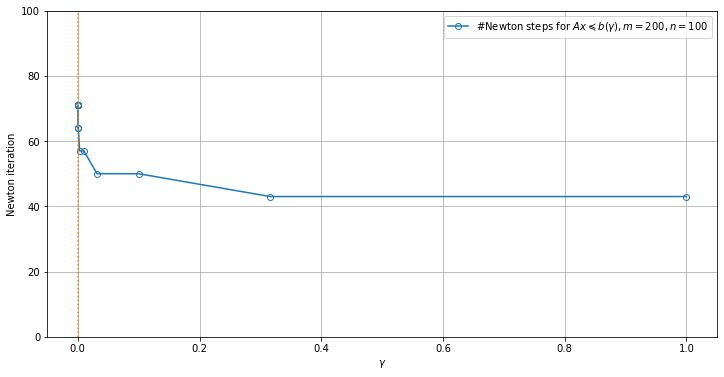

In [29]:
if __name__ == "__main__":
    plot_pos_gamma()

Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22
Info: It is infeasible at iteration = 22


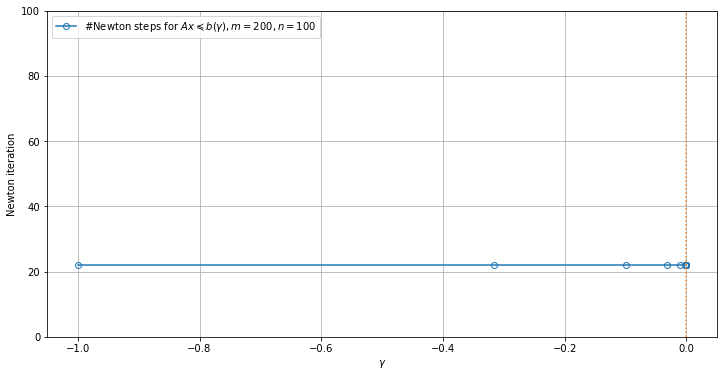

In [30]:
if __name__ == "__main__":
    plot_neg_gamma()